In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, precision_score,
    recall_score, f1_score
)

uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)

df.columns = df.columns.str.strip().str.lower()
df = df[['text', 'language']].dropna()
df['text'] = df['text'].astype(str).str.strip()
df['language'] = df['language'].astype(str).str.strip()
df = df[df['text'] != '']

print(df.shape)
print(df['language'].value_counts())

Saving archive (3).zip to archive (3) (2).zip
(21999, 2)
language
Estonian      1000
Swedish       1000
Thai          1000
Tamil         1000
Japanese      1000
Turkish       1000
Hindi         1000
Latin         1000
Urdu          1000
Indonesian    1000
Portugese     1000
French        1000
Chinese       1000
Korean        1000
Romanian      1000
Spanish       1000
Pushto        1000
Persian       1000
English       1000
Russian       1000
Arabic        1000
Dutch          999
Name: count, dtype: int64


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

encoder = LabelEncoder()
y = encoder.fit_transform(df['language'])
X_text = df['text'].values

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))
print("Number of languages:", len(encoder.classes_))

Training samples: 17599
Testing samples: 4400
Number of languages: 22


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

tokenizer = Tokenizer(
    num_words=50000,
    char_level=True,
    lower=True,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

max_length = 200

X_train = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

vocab_size = min(50000, len(tokenizer.word_index) + 1)

print("Vocabulary size:", vocab_size)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Vocabulary size: 6814
Training shape: (17599, 200)
Testing shape: (4400, 200)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Bidirectional, LSTM,
    Dense, Dropout, SpatialDropout1D
)
from tensorflow.keras.regularizers import l2

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),
    SpatialDropout1D(0.2),
    Bidirectional(LSTM(64)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(len(encoder.classes_), activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 139s 530ms/step - accuracy: 0.4298 - loss: 1.7917 - val_accuracy: 0.6756 - val_loss: 1.1011 - learning_rate: 0.0010
Epoch 2/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 127s 511ms/step - accuracy: 0.6737 - loss: 1.0069 - val_accuracy: 0.7744 - val_loss: 0.7127 - learning_rate: 0.0010
Epoch 3/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 126s 506ms/step - accuracy: 0.7301 - loss: 0.8494 - val_accuracy: 0.7455 - val_loss: 0.7884 - learning_rate: 0.0010
Epoch 4/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 130s 525ms/step - accuracy: 0.7735 - loss: 0.7389 - val_accuracy: 0.8261 - val_loss: 0.5472 - learning_rate: 0.0010
Epoch 5/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 126s 509ms/step - accuracy: 0.7815 - loss: 0.6900 - val_accuracy: 0.7830 - val_loss: 0.6902 - learning_rate: 0.0010
Epoch 6/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 124s 499ms/step - accuracy: 0.8210 - loss: 0.6036 - val_accuracy: 0.8136 - val_loss: 0.5803 - learning_rate: 0.0010
Epoch 7/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 141s 497ms/step - accura

In [ ]:
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 Score:  {f1 * 100:.2f}%")

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

138/138 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step
Accuracy:  83.55%
Precision: 84.52%
Recall:    83.55%
F1 Score:  82.75%

Classification Report:

              precision    recall  f1-score   support

      Arabic       1.00      1.00      1.00       200
     Chinese       0.99      0.99      0.99       200
       Dutch       0.61      0.22      0.32       200
     English       0.46      0.78      0.58       200
    Estonian       0.91      0.77      0.83       200
      French       0.66      0.85      0.74       200
       Hindi       0.99      0.97      0.98       200
  Indonesian       0.77      0.80      0.78       200
    Japanese       0.99      0.98      0.98       200
      Korean       1.00      0.99      0.99       200
       Latin       0.61      0.28      0.39       200
     Persian       0.98      0.98      0.98       200
   Portugese       0.51      0.82      0.63       200
      Pushto       0.97      0.94      0.96       200
    Romanian       0.71      0.71      0.71      

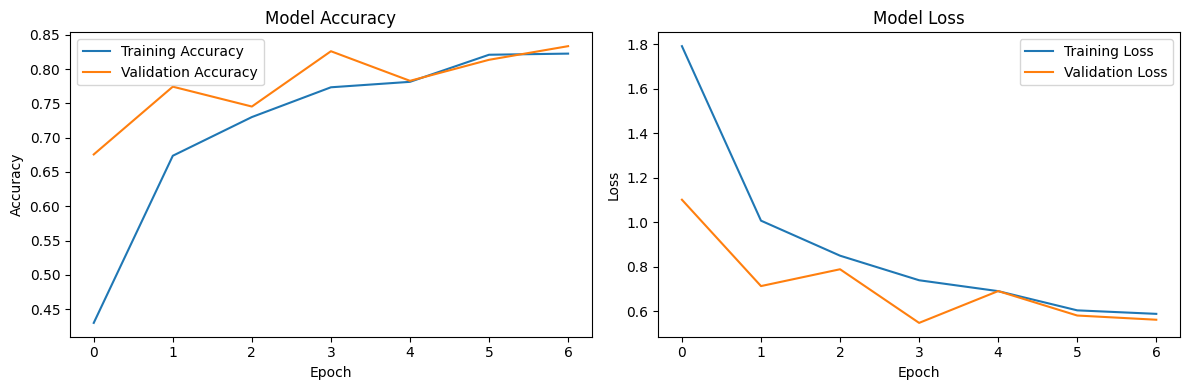

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

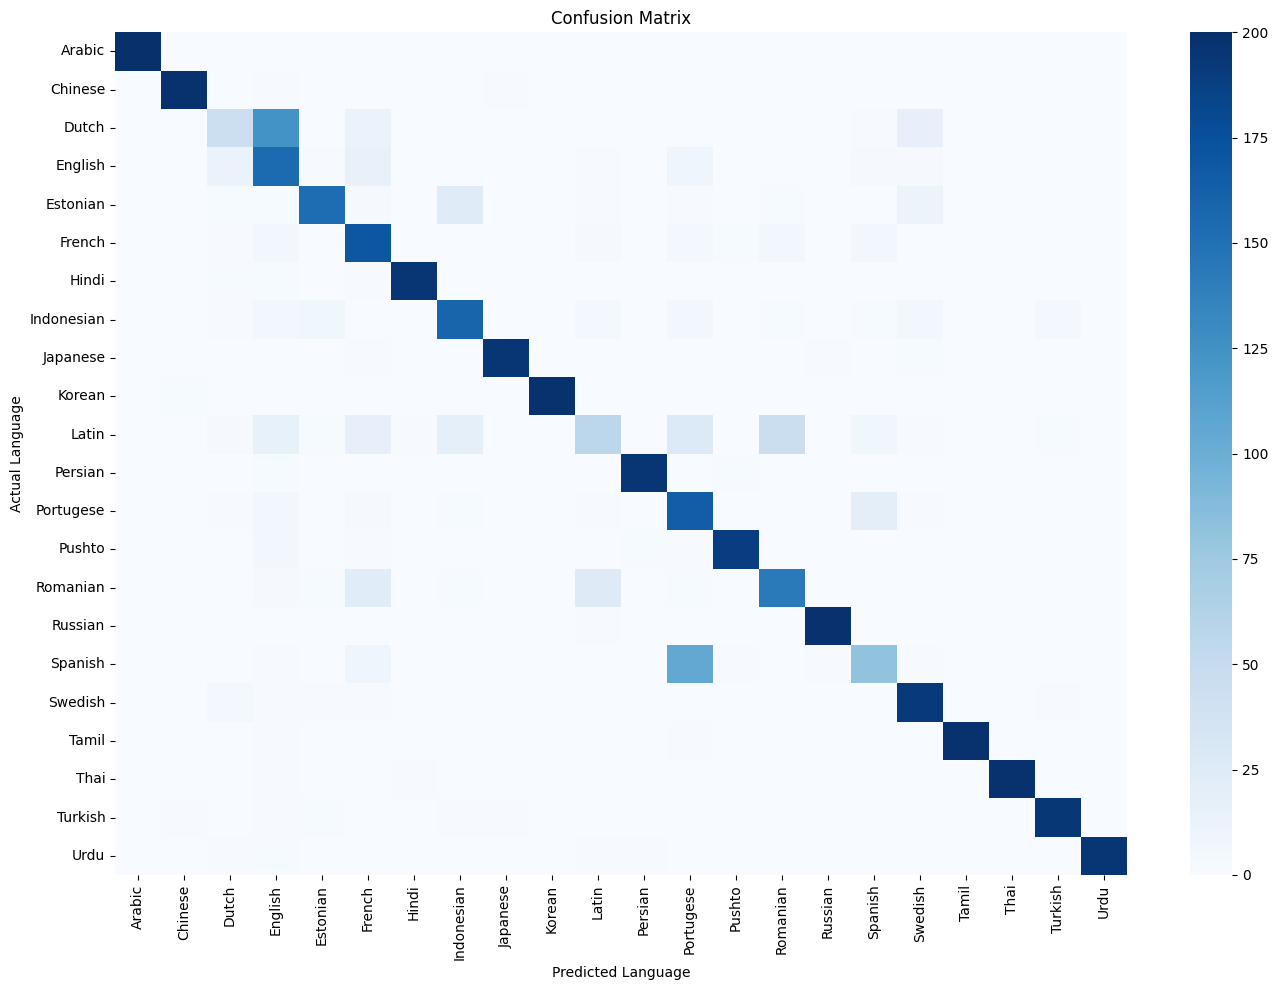

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_))
)

plt.figure(figsize=(14, 10))
sns.heatmap(
    cm,
    cmap='Blues',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Language')
plt.ylabel('Actual Language')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
unseen_texts = [
    "வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?",
    "Hello, how are you today?",
    "Bonjour, comment allez-vous?",
    "Hola, ¿cómo estás?",
    "नमस्ते, आप कैसे हैं?"
]

seq = tokenizer.texts_to_sequences(unseen_texts)
padded = pad_sequences(
    seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

predictions = model.predict(padded)
predicted_ids = np.argmax(predictions, axis=1)
confidence = np.max(predictions, axis=1)

for text, label_id, conf in zip(
    unseen_texts, predicted_ids, confidence
):
    print("Text:", text)
    print("Predicted Language:", encoder.inverse_transform([label_id])[0])
    print("Confidence:", round(float(conf) * 100, 2), "%")
    print("-" * 40)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Text: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Predicted Language: Tamil
Confidence: 99.89 %
----------------------------------------
Text: Hello, how are you today?
Predicted Language: Spanish
Confidence: 28.49 %
----------------------------------------
Text: Bonjour, comment allez-vous?
Predicted Language: Latin
Confidence: 25.56 %
----------------------------------------
Text: Hola, ¿cómo estás?
Predicted Language: Portugese
Confidence: 71.24 %
----------------------------------------
Text: नमस्ते, आप कैसे हैं?
Predicted Language: Hindi
Confidence: 99.91 %
----------------------------------------


In [ ]:
model.save("language_identification_lstm.keras")
print("Model saved successfully")

Model saved successfully
